<a href="https://colab.research.google.com/github/benjamin2138-dot/Python-Class/blob/main/QBA3720_Week10_Wednesday_HW_KNN_Campaign_Response.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QBA 3720 Week 10 Wednesday Homework — KNN Campaign Response Prediction

**Business problem:** A marketing team wants to predict whether a lead will convert.

You will practice KNN, scaling, and model comparison across several K values.


## 0. Setup
Run this cell first.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)

np.random.seed(63)

n = 260
lead_id = np.arange(60001, 60001+n)
age = np.random.randint(18, 70, n)
income = np.random.normal(68000, 22000, n).clip(22000, 160000).round(0)
website_visits = np.random.poisson(5, n)
time_on_site = np.random.normal(7.5, 3, n).clip(1, 20).round(1)
email_opens = np.random.poisson(3, n)
ad_clicks = np.random.poisson(1.5, n)
lead_source = np.random.choice(["Search", "Social", "Referral"], n, p=[0.46, 0.34, 0.20])
prior_customer = np.random.choice(["Yes", "No"], n, p=[0.30, 0.70])

referral = (lead_source == "Referral").astype(int)
prior = (prior_customer == "Yes").astype(int)

score = (
    -3.0
    + 0.000018 * income
    + 0.10 * website_visits
    + 0.13 * time_on_site
    + 0.21 * email_opens
    + 0.35 * ad_clicks
    + 0.75 * referral
    + 0.95 * prior
)

prob_convert = 1 / (1 + np.exp(-score))
converted = np.random.binomial(1, prob_convert)

leads = pd.DataFrame({
    "lead_id": lead_id,
    "age": age,
    "income": income,
    "website_visits": website_visits,
    "time_on_site": time_on_site,
    "email_opens": email_opens,
    "ad_clicks": ad_clicks,
    "lead_source": lead_source,
    "prior_customer": prior_customer,
    "converted": converted
})

leads.head()


,lead_id,age,income,website_visits,time_on_site,email_opens,ad_clicks,lead_source,prior_customer,converted
0,60001,62,104093.0,5,6.1,4,1,Social,Yes,1
1,60002,29,112427.0,8,10.2,1,0,Search,No,1
2,60003,41,39535.0,4,7.7,5,1,Search,No,1
3,60004,36,84187.0,6,6.6,2,1,Search,No,1
4,60005,50,57957.0,7,4.7,2,1,Social,No,0


## Task 1. Inspect the dataset
Show the first rows, shape, data types, conversion counts, and conversion rate.


In [2]:
(leads.head())


,lead_id,age,income,website_visits,time_on_site,email_opens,ad_clicks,lead_source,prior_customer,converted
0,60001,62,104093.0,5,6.1,4,1,Social,Yes,1
1,60002,29,112427.0,8,10.2,1,0,Search,No,1
2,60003,41,39535.0,4,7.7,5,1,Search,No,1
3,60004,36,84187.0,6,6.6,2,1,Search,No,1
4,60005,50,57957.0,7,4.7,2,1,Social,No,0


## Task 2. Prepare X and y
Create dummy variables for `lead_source` and `prior_customer`.

Define X and y.


In [3]:
leads_encoded = pd.get_dummies(leads, columns=['lead_source', 'prior_customer'], drop_first=True, dtype=int)


X = leads_encoded.drop(columns=['lead_id', 'converted'])

y = leads_encoded['converted']

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X columns:", X.columns.tolist())


X shape: (260, 9)
y shape: (260,)
X columns: ['age', 'income', 'website_visits', 'time_on_site', 'email_opens', 'ad_clicks', 'lead_source_Search', 'lead_source_Social', 'prior_customer_Yes']


## Task 3. Split and scale
Use train/test split with `test_size=0.25`, `random_state=42`, and `stratify=y`.

Then scale X using `StandardScaler`.


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Training target proportions:\n", y_train.value_counts(normalize=True))
print("Testing target proportions:\n", y_test.value_counts(normalize=True))


X_train shape: (195, 9)
X_test shape: (65, 9)
Training target proportions:
 converted
1    0.774359
0    0.225641
Name: proportion, dtype: float64
Testing target proportions:
 converted
1    0.769231
0    0.230769
Name: proportion, dtype: float64


## Task 4. Build KNN with K = 5
Fit the model and calculate accuracy, precision, recall, and F1.


In [6]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")


Accuracy:  0.7385
Precision: 0.8000
Recall:    0.8800
F1 Score:  0.8381


## Task 5. Compare K values
Try K = 3, 5, 7, 9, 11, 15.

Create a table comparing the metrics.


In [7]:
k_values = [3, 5, 7, 9, 11, 15]
results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)


    y_pred = knn.predict(X_test_scaled)


    results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

df_results = pd.DataFrame(results)
display(df_results)


,K,Accuracy,Precision,Recall,F1 Score
0,3,0.676923,0.773585,0.82,0.796117
1,5,0.738462,0.800000,0.88,0.838095
2,7,0.738462,0.770492,0.94,0.846847
3,9,0.769231,0.786885,0.96,0.864865
4,11,0.769231,0.786885,0.96,0.864865
5,15,0.753846,0.774194,0.96,0.857143


## Task 6. Visualize model performance
Create a line chart showing F1 score by K.


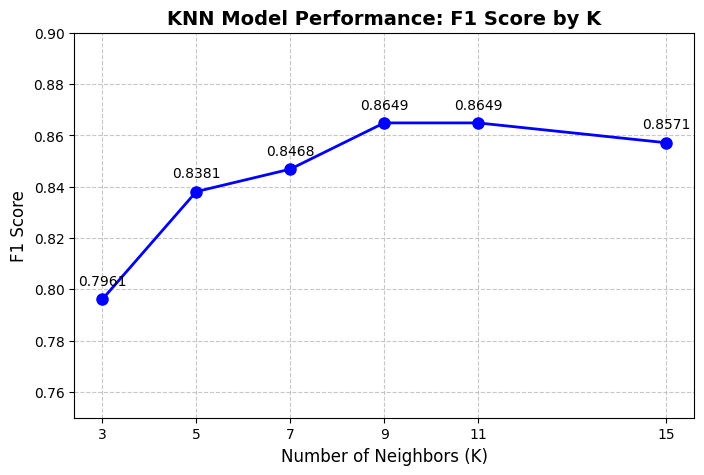

In [8]:
import matplotlib.pyplot as plt

k_values = [3, 5, 7, 9, 11, 15]
f1_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    f1_scores.append(f1_score(y_test, y_pred))

plt.figure(figsize=(8, 5))
plt.plot(k_values, f1_scores, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('KNN Model Performance: F1 Score by K', fontsize=14, fontweight='bold')
plt.xlabel('Number of Neighbors (K)', fontsize=12)
plt.ylabel('F1 Score', fontsize=12)
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.ylim(0.75, 0.90)

for i, txt in enumerate(f1_scores):
    plt.annotate(f"{txt:.4f}", (k_values[i], f1_scores[i]), textcoords="offset points", xytext=(0,10), ha='center')

plt.show()


## Task 7. Recommendation
Write 5–7 sentences explaining which K you recommend and why. Include a business explanation of precision and recall.


**Your answer:**
For this marketing campaign lead-conversion model, I recommend selecting K=9 (or equivalently K=11), as it achieves the optimal balance of overall accuracy (76.92) and the highest F1 score (0.8649) across all tested neighbors. In a business context, precision measures the proportion of predicted converting leads who actually convert, helping the marketing team avoid wasting limited sales resources and marketing budgets on unpromising prospects. Conversely, recall measures the proportion of actual converters successfully captured by the model, ensuring that the sales team misses out on as few high-potential customer opportunities as possible. Because failing to capture a potential buyer represents lost revenue while contacting a false positive incurs minor outreach costs, prioritizing a high recall rate of 0.9600 at K=9 safeguards campaign effectiveness. Ultimately, setting K=9 prevents overfitting associated with overly small neighborhoods (like K=3) while avoiding the excessive smoothing and misclassification seen in larger neighborhoods, maximizing return on marketing investment.